In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
fpaths = []
labels = []
spoken = []

In [3]:
for f in os.listdir("./Audio"):
    for w in os.listdir("./Audio/" + f):
        fpaths.append("./Audio/" + f + "/" + w)
        labels.append(f)
        if f not in spoken:
            spoken.append(f)

print("Words spoken: ", spoken)
print("Labels: ", labels)
print("fpaths spoken: ", fpaths)

Words spoken:  ['apple', 'banana', 'book', 'cat', 'dog', 'eye', 'fast', 'god', 'human', 'kiwi', 'lime']
Labels:  ['apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'apple', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'banana', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'book', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'eye', 'fast', 'fast', 'fast', 'fast',

In [4]:
from scipy.io import wavfile

In [5]:
data = np.zeros((len(fpaths), 32000))
maxsize = -1
for n, file in enumerate(fpaths):
    _, d = wavfile.read(file)
    data[n, :d.shape[0]] = d
    if d.shape[0] > maxsize:
        maxsize = d.shape[0]

data = data[:, :maxsize]

In [6]:
all_labels = np.zeros(data.shape[0])
dictionary = [""] * 14

In [7]:
for n, l in enumerate(set(labels)): 
    all_labels[np.array([i for i, value in enumerate(labels) if value == l])] = n

for i in range(0, len(all_labels)): 
    dictionary[int(all_labels[i])] = labels[i]

print("Dictionary: ", dictionary)
print("all_labels: ", all_labels)

Dictionary:  ['book', 'kiwi', 'lime', 'human', 'fast', 'banana', 'cat', 'god', 'dog', 'eye', 'apple', '', '', '']
all_labels:  [10. 10. 10. 10. 10. 10. 10. 10. 10. 10. 10. 10. 10. 10. 10. 10. 10. 10.
 10. 10. 10. 10. 10. 10. 10. 10. 10. 10. 10. 10.  5.  5.  5.  5.  5.  5.
  5.  5.  5.  5.  5.  5.  5.  5.  5.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  6.  6.  6.  6.  6.  6.  6.  6.  6.  6.  6.  6.
  6.  6.  6.  8.  8.  8.  8.  8.  8.  8.  8.  8.  8.  8.  8.  8.  8.  8.
  9.  9.  9.  9.  9.  9.  9.  9.  9.  9.  9.  9.  9.  9.  9.  4.  4.  4.
  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  4.  7.  7.  7.  7.  7.  7.
  7.  7.  7.  7.  7.  7.  7.  7.  7.  3.  3.  3.  3.  3.  3.  3.  3.  3.
  3.  3.  3.  3.  3.  3.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
  1.  1.  1.  2.  2.  2.  2.  2.  2.  2.  2.  2.]


In [8]:
import scipy

In [9]:
def stft(x, fftsize = 64, overlap_pct =.5):
    hop = int(fftsize * (1 - overlap_pct)) 
    w = scipy.hanning(fftsize + 1)[:-1] 
    raw = np.array([np.fft.rfft(w * x[i:i + fftsize]) for i in range(0, len(x) - fftsize,hop)]) 

    return raw[:, :(fftsize // 2)]

In [10]:
from scipy.signal.windows import hann

In [11]:
def stft(x, fftsize = 64, overlap_pct =.5):
    hop = int(fftsize * (1 - overlap_pct)) 
    w = hann(fftsize + 1)[:-1] 
    raw = np.array([np.fft.rfft(w * x[i:i + fftsize]) for i in range(0, len(x) - fftsize,hop)]) 

    return raw[:, :(fftsize // 2)]

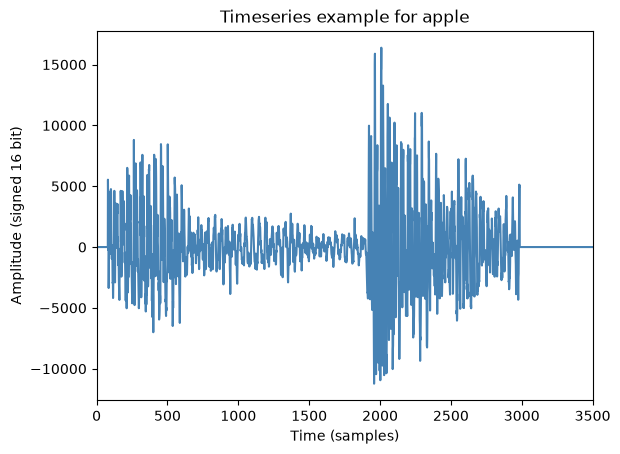

In [12]:

plt.plot(data[0, :], color="steelblue")
plt.title("Timeseries example for %s" %labels[0])
plt.xlim(0, 3500)
plt.xlabel("Time (samples)")
plt.ylabel("Amplitude (signed 16 bit)")
plt.show()

In [13]:
from numpy.lib.stride_tricks import as_strided


In [14]:
def peakfind(x, n_peaks, l_size = 3, r_size = 3, c_size = 3, f=np.mean):
    
    
    
    win_size = l_size + r_size + c_size
    shape = x.shape[:-1] + (x.shape[-1] - win_size + 1, win_size) 

    strides = x.strides + (x.shape[-1], ) 
    xs = as_strided(x, shape = shape, strides = strides) 

    def is_peak(x):
        centered = (np.argmax(x) == l_size + int(c_size / 2)) 

        l = x[:l_size]
        c = x[l_size:l_size + c_size]
        r = x[-r_size:]

        passes = np.max(c) > np.max([f(l), f(r)]) 
        if centered and passes:
            return np.max(c)
        else:
            return -1

    r = np.apply_along_axis(is_peak, 1, xs) 
    top = np.argsort(r, None)[::-1] 
    heights = r[top[:n_peaks]] 
    top[top > -1] = top[top > -1] + l_size + int(c_size / 2.) 
    return heights, top[:n_peaks]

In [15]:
all_obs = []
for i in range(data.shape[0]): 
    d = np.abs(stft(data[i, :]))
    n_dim = 6 
    obs = np.zeros((n_dim, d.shape[0]))

    
    for r in range(d.shape[0]):
        _, t = peakfind(d[r, :], n_peaks = n_dim)
        obs[:, r] = t.copy()

    
    if i % 10 == 0:
        print("Processed obs %s" %i)
    all_obs.append(obs)

all_obs = np.atleast_3d(all_obs) 

c:\SEM 5\LAB AI Semester 5\.venv\Lib\site-packages\numpy\lib\_shape_base_impl.py:413: RuntimeWarning: invalid value encountered in cast
  buff[ind] = asanyarray(func1d(inarr_view[ind], *args, **kwargs))


Processed obs 0
Processed obs 10
Processed obs 20
Processed obs 30
Processed obs 40
Processed obs 50
Processed obs 60
Processed obs 70
Processed obs 80
Processed obs 90
Processed obs 100
Processed obs 110
Processed obs 120
Processed obs 130
Processed obs 140
Processed obs 150
Processed obs 160
Processed obs 170


Membuat class GMM dan HMM yang akan digunakan untuk klasifikasi audio-audio kita.

In [16]:
import scipy.stats as st 
from scipy.stats import multivariate_normal 

In [17]:
class gmmhmm:
    def __init__(self, n_states):
        self.n_states = n_states
        self.random_state = np.random.RandomState(0)
        self.prior = self._normalize(self.random_state.rand(self.n_states, 1))
        self.A = self._stochasticize(self.random_state.rand(self.n_states, self.n_states))

        self.mu = None 
        self.covs = None 
        self.n_dims = None



    def _forward(self, B): 
        log_likelihood = 0 

        T = B.shape[1] 
        alpha = np.zeros(B.shape)

        for t in range(T):
            
            if t == 0:
                
                alpha[:, t] = B[:, t] * self.prior.ravel() 
            else:
                
                alpha[:, t] = B[:, t] * np.dot(self.A.T, alpha[:, t-1])

            
            alpha_sum = np.sum(alpha[:, t])

            alpha[:, t] /= alpha_sum

            
            log_likelihood = log_likelihood + np.log(alpha_sum)

        return log_likelihood, alpha

    
    
    def _backward(self, B):
        T = B.shape[1]
        beta = np.zeros(B.shape) 

        
        beta[:, -1] = np.ones(B.shape[0])
        for t in range(T - 1)[::-1]: 
            beta[:, t] = np.dot(self.A, (B[:, t + 1] * beta[:, t + 1])) 
            beta[:, t] /= np.sum(beta[:, t]) 
        
        return beta

    def _state_likelihood(self, obs): 
        obs = np.atleast_2d(obs) 
        B = np.zeros((self.n_states, obs.shape[1])) 
        for s in range(self.n_states): 
            np.random.seed(self.random_state.randint(1))
            
            B[s, :] = st.multivariate_normal.pdf(obs.T, mean = self.mu[:, s].T, cov = self.covs[:, :, s].T)

        return B

    def _normalize(self, x):
        return (x + (x == 0)) / np.sum(x)

    def _stochasticize(self, x): 
        return (x + (x == 0)) / np.sum(x, axis=1)


# === BATAS MULAI SESI 8 ===
# A: probabilitas perpindahan dari satu hidden state ke state lainnya
# B: likelihood fitur suara terhadap hidden state

# EM -> Ecpectation Maximization : algorithm iteratif yang memperkirakan pramater model ketika terdapat info tersembunyi

    def _em_init(self, obs):
        if self.n_dims is None:
            self.n_dims = obs.shape[0]

        if self.mu is None:
            subset = self.random_state.choice(np.arange(self.n_dims), size = self.n_states, replace = False)
            self.mu = obs[:, subset]

        if self.covs is None:
            self.covs = np.zeros((self.n_dims, self.n_dims, self.n_states))
            self.covs += np.diag(np.cov(obs))[:, :, None]

        return self

    # em_step
    # fungsi nya: mengambil 1 obs alu bakal menghitung likelihood dan alpha

    def em_step(self, obs):
        obs = np.atleast_2d(obs) 
        # hitung likelihood
        B = self._state_likelihood(obs)
        T = obs.shape[1]

        log_likelihood, alpha = self._forward(B)
        beta = self._backward(B)

        xi_sum = np.zeros((self.n_states, self.n_states))
        gamma = np.zeros((self.n_states, T))

        # looping untuk tiap time stamp
        for t in range(T-1):
            partial_sum = self.A * np.outer(alpha[:, t], (beta[:, t + 1] * B[:, t + 1]).T)
            xi_sum += self._normalize(partial_sum)
            partial_g = alpha[:, t] * beta[:, t]

            # menormalisasi gama dengan function normalize
            gamma[:, t] = self._normalize(partial_g)

        partial_g = alpha[:, t] * beta[:, t]

        gamma[:, t] = self._normalize(partial_g)

        # kalkulasi prior probabilitas yang terjadi pada kolom pertama gamma
        # expected_prior : probabilitas awal state yang memperkitakan dari gamma pada frame pertama
        expected_prior = gamma[:, 0]
        expected_A = self._stochasticize(xi_sum)
        expected_mu = np.zeros((self.n_states, self.n_states))
        self.covs = np.zeros((self.n_dims, self.n_dims, self.n_states))
        gamma_state_sum = np.sum(gamma, axis=1)
        gamma_state_sum = gamma_state_sum + (gamma_state_sum == 0)

        # looping tiap hidden state
        for s in range(self.n_states):
            gamma_obs = obs * gamma[s, :]
            expected_mu[:, s] = np.sum(gamma_obs, axis=1) / gamma_state_sum[s]
            partial_covs = np.dot(gamma_obs, obs.T) / gamma_state_sum[s] - np.dot(expected_mu[:, s], expected_mu[:, s].T)

            partial_covs = np.triu(partial_covs) + np.triu(partial_covs).T - np.diag(partial_covs)

        expected_covs += .01 * np.eye(self.n_dims)[:, :, None]
        self.prior = expected_prior
        self.mu = expected_mu
        self.covs = expected_covs
        self.A = expected_A
        return log_likelihood

    # latih parameter model
    def fit(self, obs, n_iter = 8):
        if len(obs.shape) == 2:
            for i in range(n_iter):
                self._em_init(obs)                    
                log_likelihood = self.em_step(obs)

        elif len(obs.shape) == 3:
            count = obs.shape[0]
            for i in range(n_iter):                    
                self._em_init(obs[n, :, :])
                log_likelihood = self.em_step(obs[n, :, :])

        return self

    # function transform -> dipakai untuk melakukan klasifikasi atau hiting score pengenalan suara
    def transform(self, obs):
        if len(obs.shape) == 2:
            # hitung likelihood
            B = self._state_likelihood(obs)
            log_likelihood = self._forward(B)
            return log_likelihood

        elif len(obs.shape) == 3:
            count = obs.shape[0]
            out = np.zeros((count,))
            for n in range(count):
                # hitung setiap sequence
                B = self._state_likelihood(obs[n, :, :])
                log_likelihood = self._forward(B)
                out[n] = log_likelihood
            return out

In [ ]:
import sklearn
from sklearn.model_selection import StratifiedShuffleSplit
# bagi dataset menjadi training dan testing secara acak namun dia masih mempertahankan proporsi label yang sama di kedua set (kelasnya).

In [ ]:
for n, i in enumerate(all_obs):
    all_obs[n] /= all_obs[n].sum(axis=0)

x = all_obs
y = all_labels

n_split = np.array(np.bincount(all_labels.astype(int))).sum()
sss = StratifiedShuffleSplit(0, test_size=0.1, random_state=0)

for train_index, test_index in sss.split(x, y):
    print("TRAIN:", train_index, "TEST:", test_index)
    x_train, x_test = all_obs[train_index], all_obs[test_index]
    y_train, y_test = all_labels[train_index], all_labels[test_index]

ys = set(all_labels)
ms = [gmmhmm(6) for y in ys]

# training
_ = [m.fit(x_train[y_train == y], n_iter = 8) for m, y in zip(ms, ys)]

# Melakukan klasifikasi log_likelihood dari setiap model untuk setiap data uji di vector x_test
ps = [m.transform(x_test) for m in ms]
res = np.vstack(ps)
predicted_labels = np.argmax(res, axis=0)
# dapet missed classification rate
missed = (predicted_labels != y_test)
print("Test Accuracy: %.2f" % (100 * (1 - np.mean(missed))))

In [ ]:
maxsize = 32000
new_data = np.zeros(maxsize)
_, new_d = wavfile.read("./Audio/apple/apple12.wav")
new_data[:new_d.shape[0]] = new_d
new_data = new_data[:maxsize]

observation = []

# kalkulasi stft dari data baru
new_d = np.abs(stft(new_data))
n_dim = 6
new_obs = np.zeros((n_dim, new_d.shape[0]))

# cari peak tertinggi PeakFind
for r in range(new_d.shape[0]):
    _, t = peakfind(new_d[r, :], n_peaks = n_dim)
    new_obs[:, r] = t.copy()
